# 03 - Ad monetisation

**Goal.** Measure how much the game earns from ads, how well ads are delivered, and whether early ad exposure is linked to retention.

**Reading rule.** Revenue figures are estimates reported by the ad networks (`amount`, in USD), not cash received. The link between ads and retention is a correlation: players who play more see more ads, so exposure is compared between players with a similar level of play.

In [15]:
import sys
sys.path.append("../scripts")
from load_events import connect_events
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

con, readable, unreadable = connect_events("../data/raw/player_analytics/*.parquet")
print(len(readable), "readable files,", len(unreadable), "unreadable")

67 readable files, 1 unreadable


## 1. Ad impressions table

The revenue of an impression is stored in `event_properties`, which is a text map. It sits under the key `value` in the first weeks and under the key `amount` later (the two never appear together in the data checked). Both are read with `COALESCE(amount, value)`.

Values are text. Some phones write the decimal separator as a comma (`0,0141`) or even a slash (`0/0096`): both are converted to a dot before casting; the cell reports how many values still fail.

In [16]:
con.execute("""
    CREATE OR REPLACE TABLE ads AS
    SELECT user_id,
           user_session_id,
           ts,
           CAST(ts AS DATE)                    AS day,
           client_platform                     AS platform,
           event_properties['adFormat']        AS ad_format,
           event_properties['adSource']        AS ad_source,
           event_properties['amount'] IS NOT NULL AS has_amount_key,
           event_properties['value']  IS NOT NULL AS has_value_key,
           COALESCE(event_properties['amount'], event_properties['value']) AS amount_text,
           TRY_CAST(REPLACE(REPLACE(COALESCE(event_properties['amount'], event_properties['value']), ',', '.'), '/', '.') AS DOUBLE) AS amount_usd
    FROM events
    WHERE event_name = 'adImpression'
""")
con.sql("""
    SELECT COUNT(*)                                                        AS impressions,
           COUNT(*) FILTER (WHERE amount_text IS NULL)                     AS no_revenue_value,
           COUNT(*) FILTER (WHERE amount_text IS NOT NULL AND amount_usd IS NULL) AS unparsable,
           COUNT(*) FILTER (WHERE has_amount_key AND has_value_key)        AS both_keys,
           COUNT(*) FILTER (WHERE amount_text LIKE '%,%' OR amount_text LIKE '%/%') AS non_dot_decimal,
           COUNT(*) FILTER (WHERE amount_usd > 1)                          AS above_1_usd
    FROM ads
""").show(max_width=200)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────┬──────────────────┬────────────┬───────────┬─────────────────┬─────────────┐
│ impressions │ no_revenue_value │ unparsable │ both_keys │ non_dot_decimal │ above_1_usd │
│    int64    │      int64       │   int64    │   int64   │      int64      │    int64    │
├─────────────┼──────────────────┼────────────┼───────────┼─────────────────┼─────────────┤
│     1900860 │                0 │          0 │         0 │          640762 │        1737 │
└─────────────┴──────────────────┴────────────┴───────────┴─────────────────┴─────────────┘



Impressions with no revenue value or an unparsable one are kept in counts but add 0 to revenue. `both_keys` should be 0 (otherwise `amount` takes priority). A single impression above 1 USD is unusual: the count is shown so that outliers are not a surprise. The unit of `value` is assumed to be the same as `amount` (USD, as `currency` says): the daily eCPM in the coverage check below should have no jump at the switch.

### Coverage check: which key carries the revenue, and when?

Does the revenue key change over time, and is the revenue per 1,000 impressions (eCPM) continuous when it does? And did the app version change around the data gap of 2025-03-27?

In [17]:
df_cov = con.execute("""
    SELECT day, COUNT(*) AS impressions,
           ROUND(100.0 * COUNT(*) FILTER (WHERE has_value_key)  / COUNT(*), 1) AS pct_value_key,
           ROUND(100.0 * COUNT(*) FILTER (WHERE has_amount_key) / COUNT(*), 1) AS pct_amount_key,
           ROUND(100.0 * COUNT(amount_usd) / COUNT(*), 1)                       AS pct_usable,
           ROUND(AVG(amount_usd) * 1000, 1)                                     AS ecpm_usd
    FROM ads GROUP BY 1 ORDER BY 1
""").df()
df_cov

,day,impressions,pct_value_key,pct_amount_key,pct_usable,ecpm_usd
0,2025-02-28,23662,100.0,0.0,100.0,19.9
1,2025-03-01,56150,100.0,0.0,100.0,18.3
2,2025-03-02,57037,100.0,0.0,100.0,20.0
3,2025-03-03,44856,100.0,0.0,100.0,18.6
4,2025-03-04,57015,100.0,0.0,100.0,16.8
5,2025-03-05,58338,100.0,0.0,100.0,16.7
6,2025-03-06,60968,100.0,0.0,100.0,16.7
7,2025-03-07,55160,100.0,0.0,100.0,15.8
8,2025-03-08,54196,100.0,0.0,100.0,18.7
9,2025-03-09,52281,100.0,0.0,100.0,18.1


In [18]:
df_ver = con.execute("""
    SELECT CAST(ts AS DATE) AS day,
           user_properties_custom['appVersion'] AS app_version,
           COUNT(DISTINCT user_id) AS players
    FROM events
    WHERE CAST(ts AS DATE) BETWEEN DATE '2025-03-22' AND DATE '2025-04-02'
    GROUP BY 1, 2
""").df()
top_versions = df_ver.groupby("app_version")["players"].sum().nlargest(6).index
df_ver[df_ver["app_version"].isin(top_versions)].pivot(index="day", columns="app_version", values="players").fillna(0).astype(int)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

app_version,0.21.15,0.21.16,0.21.19,0.21.20,0.21.21,0.21.23
day,,,,,,
2025-03-22,72,78,87,248,3639,0
2025-03-23,72,80,86,228,4385,0
2025-03-24,52,48,54,159,3651,0
2025-03-25,49,41,38,161,3969,0
2025-03-26,51,48,30,135,3304,0
2025-03-27,9,8,15,39,1355,4
2025-03-28,63,68,40,146,3361,14
2025-03-29,74,69,61,173,3706,726
2025-03-30,66,67,57,170,2217,3467


If `pct_value_key` falls and `pct_amount_key` rises on the same days, the property was renamed (an app update or SDK change). `pct_usable` should stay near 100 throughout, and `ecpm_usd` should not jump at the switch: a jump would mean the two keys do not measure the same thing. If a new `app_version` appears right at the data gap, that is a lead for its cause, not a proof.

## 2. Revenue by format and network

`INTER` is an interstitial (forced, full screen); `REWARDED` is a video the player chooses to watch for a reward.

In [19]:
con.sql("""
    SELECT ad_format,
           COUNT(*)                          AS impressions,
           ROUND(SUM(amount_usd), 0)         AS revenue_usd,
           ROUND(AVG(amount_usd) * 1000, 1)  AS ecpm_usd
    FROM ads
    GROUP BY 1
    ORDER BY 3 DESC
""").show(max_width=200)

con.sql("""
    SELECT ad_source,
           COUNT(*)                          AS impressions,
           ROUND(SUM(amount_usd), 0)         AS revenue_usd,
           ROUND(AVG(amount_usd) * 1000, 1)  AS ecpm_usd
    FROM ads
    GROUP BY 1
    ORDER BY 3 DESC
    LIMIT 10
""").show(max_width=200)

┌───────────┬─────────────┬─────────────┬──────────┐
│ ad_format │ impressions │ revenue_usd │ ecpm_usd │
│  varchar  │    int64    │   double    │  double  │
├───────────┼─────────────┼─────────────┼──────────┤
│ REWARDED  │      783442 │     22761.0 │     29.1 │
│ INTER     │     1117418 │     15656.0 │     14.0 │
└───────────┴─────────────┴─────────────┴──────────┘

┌───────────────────┬─────────────┬─────────────┬──────────┐
│     ad_source     │ impressions │ revenue_usd │ ecpm_usd │
│      varchar      │    int64    │   double    │  double  │
├───────────────────┼─────────────┼─────────────┼──────────┤
│ AppLovin          │      985073 │     22136.0 │     22.5 │
│ Mintegral         │      217827 │      5619.0 │     25.8 │
│ Google AdMob      │      255824 │      4153.0 │     16.2 │
│ Facebook          │      104816 │      2617.0 │     25.0 │
│ APPLOVIN_EXCHANGE │       88165 │      1087.0 │     12.3 │
│ Google Ad Manager │       58729 │      1021.0 │     17.4 │
│ Liftoff Monetize

`ecpm_usd` is revenue per 1,000 impressions, the usual way to compare ad networks.

## 3. Ad revenue per active player and per day

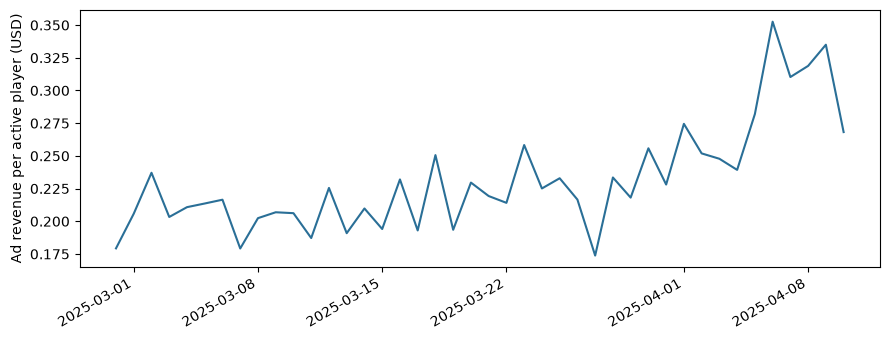

,day,dau,impressions,revenue_usd,revenue_per_active_player,impressions_per_active_player
mean,2025-03-20 12:00:00,3916.881,45258.571,914.69,0.232,11.455
min,2025-02-28 00:00:00,1410.000,13494.000,245.00,0.174,9.020
max,2025-04-10 00:00:00,5001.000,60968.000,1539.00,0.353,13.130


In [20]:
df_rev = con.execute("""
    WITH dau AS (SELECT CAST(ts AS DATE) AS day, COUNT(DISTINCT user_id) AS dau FROM events GROUP BY 1),
         rev AS (SELECT day, SUM(amount_usd) AS revenue, COUNT(*) AS impressions FROM ads GROUP BY 1)
    SELECT d.day, d.dau, r.impressions, ROUND(r.revenue, 0) AS revenue_usd,
           ROUND(r.revenue / d.dau, 4)      AS revenue_per_active_player,
           ROUND(1.0 * r.impressions / d.dau, 2) AS impressions_per_active_player
    FROM dau d JOIN rev r USING (day)
    ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df_rev["day"], df_rev["revenue_per_active_player"], color="#2a6f97")
ax.set_ylabel("Ad revenue per active player (USD)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
df_rev.describe().round(3).loc[["mean", "min", "max"]]

A flat line means revenue follows the number of players; a rise or fall means the revenue per player changed. 2025-03-27 is a data gap, and 2025-02-28 and 2025-04-10 are partial days.

## 4. Ad delivery quality

Each ad goes through states (`AdLoaded`, `AdDisplayed`, `AdRevenuePaid`, ...). The load failure rate shows how often an ad could not be shown, a lost revenue opportunity and a useful tracking indicator.

In [21]:
con.sql("""
    SELECT event_name AS lifecycle,
           event_properties['state'] AS state,
           COUNT(*) AS events
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
    GROUP BY 1, 2
    ORDER BY 1, 3 DESC
""").show(max_rows=30, max_width=200)

con.sql("""
    SELECT event_name AS lifecycle,
           ROUND(100.0 * COUNT(*) FILTER (WHERE event_properties['state'] = 'AdLoadFailed')
                 / COUNT(*) FILTER (WHERE event_properties['state'] IN ('AdLoaded', 'AdLoadFailed')), 1) AS load_failure_pct
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
    GROUP BY 1
""").show(max_width=200)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────┬──────────────────┬─────────┐
│       lifecycle       │      state       │ events  │
│        varchar        │     varchar      │  int64  │
├───────────────────────┼──────────────────┼─────────┤
│ interstitialLifecycle │ AdLoaded         │ 1264795 │
│ interstitialLifecycle │ AdRevenuePaid    │ 1118189 │
│ interstitialLifecycle │ AdHidden         │ 1032392 │
│ interstitialLifecycle │ AdDisplayed      │ 1031316 │
│ interstitialLifecycle │ AdClicked        │  650067 │
│ interstitialLifecycle │ AdLoadFailed     │   32286 │
│ interstitialLifecycle │ AdDisplayFailed  │     560 │
│ rvLifecycle           │ AdLoaded         │  993771 │
│ rvLifecycle           │ AdRevenuePaid    │  783748 │
│ rvLifecycle           │ AdDisplayed      │  751728 │
│ rvLifecycle           │ AdHidden         │  751680 │
│ rvLifecycle           │ AdReceivedReward │  733521 │
│ rvLifecycle           │ AdClicked        │  404531 │
│ rvLifecycle           │ AdLoadFailed     │   40566 │
│ rvLifecy

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────┬──────────────────┐
│       lifecycle       │ load_failure_pct │
│        varchar        │      double      │
├───────────────────────┼──────────────────┤
│ rvLifecycle           │              3.9 │
│ interstitialLifecycle │              2.5 │
└───────────────────────┴──────────────────┘



In [22]:
con.sql("""
    SELECT event_properties['errorInfo'] AS error, COUNT(*) AS events
    FROM events
    WHERE event_name IN ('interstitialLifecycle', 'rvLifecycle')
      AND event_properties['errorInfo'] <> 'no error'
    GROUP BY 1
    ORDER BY 2 DESC
    LIMIT 8
""").show(max_width=250)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────────────────────────────────────────────────────────────────┬────────┐
│                                       error                                       │ events │
│                                      varchar                                      │ int64  │
├───────────────────────────────────────────────────────────────────────────────────┼────────┤
│ Failed to connect to ms.applvn.com/[::]:443                                       │  16867 │
│ Unable to resolve host "ms.applovin.com": No address associated with hostname     │  15941 │
│ Failed to connect to ms.applvn.com/0.0.0.0:443                                    │  10675 │
│ Failed to connect to ms.applvn.com/127.0.0.1:443                                  │   6483 │
│ NSURLErrorDomain=-1000 : bad URL                                                  │   4013 │
│ NSURLErrorDomain=-1003 : A server with the specified hostname could not be found. │   2780 │
│ Unable to resolve host "ms4.applovin.com": No ad

Most errors look like network problems (host not resolved, connection reset): they are not necessarily a defect of the game. Do not conclude more than that.

## 5. Early ad exposure and next-day retention

**Population.** New players (`firstOpen`, as in notebook 02). **Exposure.** Interstitials seen on the first day. **Outcome.** Active the next day (D1). The cohorts of 2025-03-26 and 2025-03-27 are excluded: their next day falls in the data gap and would look like churn.

In [23]:
LAST_FULL_DAY = "2025-04-09"
con.execute("""
    CREATE OR REPLACE TABLE new_players AS
    SELECT user_id, CAST(MIN(ts) AS DATE) AS cohort_day
    FROM events WHERE event_name = 'firstOpen' GROUP BY 1
""")
con.execute("""
    CREATE OR REPLACE TABLE active_days AS
    SELECT DISTINCT user_id, CAST(ts AS DATE) AS day FROM events
""")
con.execute(f"""
    CREATE OR REPLACE TABLE day0 AS
    SELECT p.user_id,
           p.cohort_day,
           COALESCE(a.inter, 0)     AS inter_day0,
           COALESCE(a.rewarded, 0)  AS rewarded_day0,
           COALESCE(s.sessions, 0)  AS sessions_day0,
           (d1.user_id IS NOT NULL) AS retained_d1
    FROM new_players p
    LEFT JOIN (SELECT user_id, day,
                      COUNT(*) FILTER (WHERE ad_format = 'INTER')    AS inter,
                      COUNT(*) FILTER (WHERE ad_format = 'REWARDED') AS rewarded
               FROM ads GROUP BY 1, 2) a ON a.user_id = p.user_id AND a.day = p.cohort_day
    LEFT JOIN (SELECT user_id, CAST(ts AS DATE) AS day, COUNT(DISTINCT user_session_id) AS sessions
               FROM events WHERE user_session_id <> '' GROUP BY 1, 2) s ON s.user_id = p.user_id AND s.day = p.cohort_day
    LEFT JOIN active_days d1 ON d1.user_id = p.user_id AND d1.day = p.cohort_day + 1
    WHERE p.cohort_day + 1 <= DATE '{LAST_FULL_DAY}'
      AND p.cohort_day NOT IN (DATE '2025-03-26', DATE '2025-03-27')
""")
con.sql("SELECT COUNT(*) AS players, ROUND(100.0 * AVG(retained_d1::INT), 1) AS d1_pct FROM day0").show()

┌─────────┬────────┐
│ players │ d1_pct │
│  int64  │ double │
├─────────┼────────┤
│   44170 │   37.0 │
└─────────┴────────┘



In [24]:
def d1_by(column, bins, labels, where="", table="day0"):
    df = con.execute(f"""
        SELECT CASE {" ".join(f"WHEN {column} {b} THEN '{l}'" for b, l in zip(bins, labels))} END AS bucket,
               COUNT(*) AS players, SUM(retained_d1::INT) AS retained
        FROM {table} {where}
        GROUP BY 1
    """).df()
    df["d1_pct"] = (100 * df["retained"] / df["players"]).round(1)
    ci = [proportion_confint(r, p, method="wilson") for r, p in zip(df["retained"], df["players"])]
    df["ci_low"] = [round(100 * c[0], 1) for c in ci]
    df["ci_high"] = [round(100 * c[1], 1) for c in ci]
    return df.set_index("bucket").reindex(labels).reset_index()

BINS = ["= 0", "BETWEEN 1 AND 2", "BETWEEN 3 AND 5", ">= 6"]
LABELS = ["0", "1-2", "3-5", "6+"]
d1_by("inter_day0", BINS, LABELS)

,bucket,players,retained,d1_pct,ci_low,ci_high
0,0,10760,2560.0,23.8,23.0,24.6
1,1-2,9504,2636.0,27.7,26.8,28.6
2,3-5,7615,2619.0,34.4,33.3,35.5
3,6+,16291,8528.0,52.3,51.6,53.1


This table alone is misleading: a player who plays longer sees more interstitials and is also more likely to return. The next table compares players **with the same number of sessions on the first day**.

In [25]:
frames = []
for lab, cond in [("1 session", "= 1"), ("2 sessions", "= 2"), ("3+ sessions", ">= 3")]:
    f = d1_by("inter_day0", BINS, LABELS, where=f"WHERE sessions_day0 {cond}")
    f.insert(0, "day0_sessions", lab)
    frames.append(f)
by_sessions = pd.concat(frames, ignore_index=True)
by_sessions

,day0_sessions,bucket,players,retained,d1_pct,ci_low,ci_high
0,1 session,0,8618,1856.0,21.5,20.7,22.4
1,1 session,1-2,7381,1885.0,25.5,24.6,26.5
2,1 session,3-5,5104,1612.0,31.6,30.3,32.9
3,1 session,6+,6439,2852.0,44.3,43.1,45.5
4,2 sessions,0,1492,465.0,31.2,28.9,33.6
5,2 sessions,1-2,1534,489.0,31.9,29.6,34.3
6,2 sessions,3-5,1675,608.0,36.3,34.0,38.6
7,2 sessions,6+,4502,2257.0,50.1,48.7,51.6
8,3+ sessions,0,650,239.0,36.8,33.2,40.5
9,3+ sessions,1-2,589,262.0,44.5,40.5,48.5


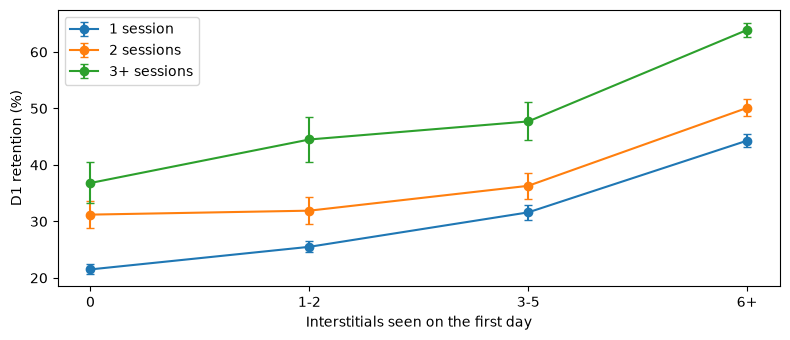

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for lab, g in by_sessions.groupby("day0_sessions"):
    g = g[g["players"] >= 200]
    ax.errorbar(g["bucket"], g["d1_pct"], yerr=[g["d1_pct"] - g["ci_low"], g["ci_high"] - g["d1_pct"]], marker="o", capsize=3, label=lab)
ax.set_xlabel("Interstitials seen on the first day")
ax.set_ylabel("D1 retention (%)")
ax.legend()
plt.tight_layout()
plt.show()

Cells with fewer than 200 players are hidden from the chart: below that, intervals are too wide to read. Rewarded ads are chosen by the player, so they measure interest rather than annoyance; the same table can be built with `rewarded_day0`.

In [27]:
d1_by("rewarded_day0", ["= 0", "BETWEEN 1 AND 2", "BETWEEN 3 AND 5", ">= 6"], LABELS)

,bucket,players,retained,d1_pct,ci_low,ci_high
0,0,14899,4321.0,29.0,28.3,29.7
1,1-2,11603,3805.0,32.8,31.9,33.7
2,3-5,7371,3014.0,40.9,39.8,42.0
3,6+,10297,5203.0,50.5,49.6,51.5


### Control for how much the player plays

The number of sessions is a rough measure of play. A better one is the number of gameplay events on the first day (events that are not ads, background events or technical `_` events). Players are split into four equal groups (quartiles) by this number, and exposure is compared inside each group.

In [28]:
con.execute("""
    CREATE OR REPLACE TABLE day0_play AS
    SELECT e.user_id, COUNT(*) AS play_events
    FROM events e
    JOIN new_players p ON p.user_id = e.user_id AND CAST(e.ts AS DATE) = p.cohort_day
    WHERE e.event_name NOT LIKE '\\_%' ESCAPE '\\'
      AND e.event_name NOT IN ('adImpression', 'adsStart', 'adsReturned', 'interstitialLifecycle',
                               'rvLifecycle', 'rvRewardClaim', 'appBackground', 'appFocus')
    GROUP BY 1
""")
con.execute("""
    CREATE OR REPLACE TABLE day0_q AS
    SELECT d.*, NTILE(4) OVER (ORDER BY COALESCE(pl.play_events, 0)) AS play_quartile
    FROM day0 d LEFT JOIN day0_play pl USING (user_id)
""")
frames = []
for q in (1, 2, 3, 4):
    f = d1_by("inter_day0", BINS, LABELS, where=f"WHERE play_quartile = {q}", table="day0_q")
    f.insert(0, "play_quartile", q)
    frames.append(f)
by_play = pd.concat(frames, ignore_index=True)
by_play

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,play_quartile,bucket,players,retained,d1_pct,ci_low,ci_high
0,1,0,7689,1521.0,19.8,18.9,20.7
1,1,1-2,3307,766.0,23.2,21.8,24.6
2,1,3-5,45,12.0,26.7,16.0,41.0
3,1,6+,2,1.0,50.0,9.5,90.5
4,2,0,1713,459.0,26.8,24.8,28.9
5,2,1-2,5209,1438.0,27.6,26.4,28.8
6,2,3-5,4003,1251.0,31.3,29.8,32.7
7,2,6+,118,39.0,33.1,25.2,42.0
8,3,0,846,315.0,37.2,34.0,40.5
9,3,1-2,719,281.0,39.1,35.6,42.7


Quartile 1 is the least active group, quartile 4 the most active. If D1 still rises with exposure inside each quartile, exposure still carries information beyond play volume (for example play time or a different kind of player); if the lines become flat, the earlier gradient was mostly play volume. Neither result proves that ads cause retention or churn.

## Findings

- **Where the revenue is stored.** The ad revenue of an impression is under the key `value` until 2025-03-28 (100% of impressions), under both keys on 2025-03-29 (85.3% `value`, 14.7% `amount`) and under `amount` from 2025-03-30 (98.5%, then about 100%). With `COALESCE(amount, value)`, every one of the 1,900,860 impressions has a usable revenue, on all 42 days.
- **Revenue.** About 38,400 USD of estimated ad revenue over six weeks. Rewarded videos bring 22,761 USD from 41% of impressions (eCPM, the revenue per 1,000 impressions, is 29.1 USD); interstitials bring 15,656 USD (eCPM 14.0). By network, AppLovin is the largest (22,136 USD, eCPM 22.5); Mintegral (25.8) and Facebook (25.0) pay more per impression; AdMob (16.2), Liftoff (10.1) and Pangle (7.3) pay less.
- **Revenue per active player.** On average 0.23 USD per active player per day (range 0.17 to 0.35), with 11.5 impressions per active player per day (range 9.0 to 13.1). These are estimates reported by the ad networks, not cash received.
- **A shift in level after the rename.** eCPM is about 27% higher from 2025-03-31 than before 2025-03-29, in both formats (rewarded 27.0 to 34.1 USD, interstitial 12.9 to 16.6 USD). It may be real (new app version 0.21.23, new ad configuration) or due to a change in how the value is measured; the data do not say which. Do not compare revenue before and after as if it were one series.
- **Outliers.** 1,737 impressions are above 1 USD each and add up to about 2,700 USD (about 7% of revenue); a version of the revenue capped at 1 USD per impression is given for the tests.
- **Delivery.** Load failures are 3.9% for rewarded videos and 2.5% for interstitials. The most frequent errors are network ones (host not resolved, connection to `127.0.0.1` or `0.0.0.0`); the latter pattern could come from DNS filtering or ad blockers (not verified).
- **Early exposure and retention.** Among 44,170 new players, D1 rises with first-day interstitials: 23.8% with none, 27.7% with 1 to 2, 34.4% with 3 to 5 and 52.3% with 6 or more. Most of this gradient is play volume: when players are split into four groups by first-day gameplay events, D1 goes from 19.8% to 51.9% between the least and most active groups with no ads at all, while inside a group the difference between none and 6 or more interstitials is about 3 to 7 points (51.9% to 58.5% in the most active group; 37.0% to 42.9% in the third). Rewarded ads show the same pattern before controls (29.0% with none, 50.5% with 6 or more).
- **What this does and does not say.** Nothing in these data shows that ads push new players away: within comparable play levels, more ads go with equal or slightly higher D1. This does not prove ads help retention; exposure still reflects how long a player stays, and some cells are small (2 players with 6 or more ads in the least active group). The only controlled comparison is the experiment of notebook 05.
- **The 2025-03-27 gap is not specific to one app version.** On that day players fall by about 60% in every version (1,355 against about 3,500 in 0.21.21; 9 against about 50 in 0.21.15), so a bug of the new version does not explain it. Version 0.21.23 first appears that day (4 players), which may be a coincidence; the cause remains unknown.

**Limits.**
- Revenue is an estimate reported by the ad networks, not cash received.
- Revenue before and after 2025-03-29 may not be comparable (see above).
- Exposure and retention are both driven by how much a player plays; the controls reduce this effect but do not remove it.
- Cohorts of 2025-03-26 and 2025-03-27 are excluded because of the data gap.